# Baseline: ResNet-18 linear probe trên CIFAR-10 (5k ảnh)

**Bài tập lớn Deep Neural Networks.** Notebook này dùng để:

1. **Định nghĩa dữ liệu chuẩn** (`make_splits`) mà mọi nhóm phải dùng: 5.000 ảnh train, 5.000 ảnh val, 10.000 ảnh test.
2. **Huấn luyện mô hình baseline:** ResNet-18 pretrained ImageNet, đóng băng backbone, chỉ train lớp `fc` (linear probe), SGD lr cố định, không augmentation.
3. **Cung cấp khung code** để các nhóm phát triển tiếp: sanity check, vòng train/eval, lưu checkpoint, hàm `predict()` cho demo.

> Trên Colab: **Runtime → Change runtime type → T4 GPU**. Chạy toàn bộ notebook mất khoảng 5–10 phút.

**Lưu ý:** baseline cố ý đơn giản. Mọi lựa chọn ở đây (optimizer, LR, số epoch, đóng băng backbone, không augmentation, …) đều có thể và nên được cải thiện.

## 1. Thiết lập

In [3]:
from google.colab import drive
import os

drive.mount('/content/drive')
# Trỏ vào đúng thư mục dự án của bạn
%cd /content/drive/MyDrive/CuoiKyDL&NR

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/CuoiKyDL&NR


In [4]:
import json
import math
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

print("torch", torch.__version__, "| torchvision", torchvision.__version__)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

torch 2.14.1+cu130 | torchvision 0.29.1+cu130
device: cuda


In [5]:
CFG = dict(
    seed=0,               # seed cho khởi tạo và thứ tự batch (KHÁC với seed chia dữ liệu, luôn là 42)
    img_size=224,         # ResNet-18 được pretrain với ảnh 224x224
    batch_size=128,
    epochs=10,
    lr=0.01,
    momentum=0.0,
    weight_decay=0.0,
    train_fraction=1.0,   # 0.01 / 0.1 / 1.0 cho thí nghiệm C2
    num_workers=2,
    data_dir="./data",
    out_dir="./outputs",
)
os.makedirs(CFG["out_dir"], exist_ok=True)
set_seed(CFG["seed"])

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

## 2. Dữ liệu

**Không được sửa** hàm `make_splits`. Mọi nhóm phải dùng đúng chỉ số này để kết quả so sánh được với nhau. Cell bên dưới in ra *checksum* để tự kiểm tra.

In [6]:
def make_splits(targets, seed=42, n_per_class=500):
    """Chia tập train gốc CIFAR-10 (50k) thành train 500 ảnh/lớp và val 500 ảnh/lớp, không trùng nhau."""
    rng = np.random.RandomState(seed)
    targets = np.asarray(targets)
    train_idx, val_idx = [], []
    for c in range(10):
        idx = np.where(targets == c)[0]
        rng.shuffle(idx)
        train_idx.append(idx[:n_per_class])
        val_idx.append(idx[n_per_class:2 * n_per_class])
    return np.concatenate(train_idx), np.concatenate(val_idx)


def subsample(indices, targets, fraction):
    """Lấy `fraction` số ảnh của mỗi lớp (tập nhỏ luôn là tập con của tập lớn)."""
    targets = np.asarray(targets)
    k = max(1, round(500 * fraction))
    return np.concatenate([indices[targets[indices] == c][:k] for c in range(10)])

In [7]:
# Transform: baseline KHÔNG dùng augmentation, nên train và eval giống nhau.
# Các nhóm có thể thêm augmentation vào train_tf (KHÔNG thêm vào eval_tf).
train_tf = T.Compose([
    T.Resize(CFG["img_size"]),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = T.Compose([
    T.Resize(CFG["img_size"]),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Hai đối tượng dataset trỏ vào cùng tập train gốc nhưng khác transform.
full_train_aug = torchvision.datasets.CIFAR10(CFG["data_dir"], train=True, download=True, transform=train_tf)
full_train_eval = torchvision.datasets.CIFAR10(CFG["data_dir"], train=True, download=False, transform=eval_tf)
test_set = torchvision.datasets.CIFAR10(CFG["data_dir"], train=False, download=True, transform=eval_tf)

targets = np.asarray(full_train_aug.targets)
train_idx, val_idx = make_splits(targets)
train_idx = subsample(train_idx, targets, CFG["train_fraction"])

assert len(set(train_idx) & set(val_idx)) == 0, "train và val bị trùng!"
print(f"train: {len(train_idx)} | val: {len(val_idx)} | test: {len(test_set)}")
print("checksum train/val:", int(make_splits(targets)[0].sum()), int(val_idx.sum()))
print("số ảnh mỗi lớp (train):", np.bincount(targets[train_idx], minlength=10))

train_set = Subset(full_train_aug, train_idx)
val_set = Subset(full_train_eval, val_idx)

loader_kw = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"], pin_memory=device.type == "cuda")
train_loader = DataLoader(train_set, shuffle=True, drop_last=False, **loader_kw)
val_loader = DataLoader(val_set, shuffle=False, **loader_kw)
test_loader = DataLoader(test_set, shuffle=False, **loader_kw)

train: 5000 | val: 5000 | test: 10000
checksum train/val: 124912918 124775163
số ảnh mỗi lớp (train): [500 500 500 500 500 500 500 500 500 500]


### Sanity check 1: nhìn dữ liệu thật sự đi vào mô hình
Luôn hiển thị **batch sau transform** (không phải ảnh gốc) kèm nhãn, để phát hiện lỗi normalize, lỗi nhãn, augmentation quá mạnh, …

batch: (128, 3, 224, 224) torch.float32 | min -2.12 max 2.64 mean 0.07 std 1.10


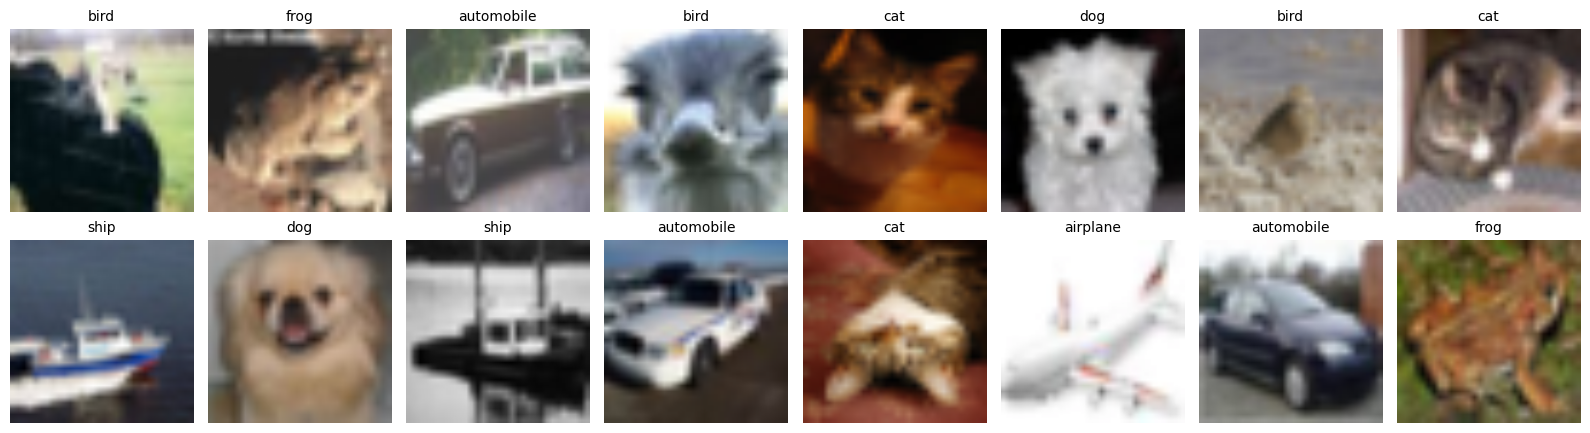

In [8]:
def denormalize(x):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1)


xb, yb = next(iter(train_loader))
print("batch:", tuple(xb.shape), xb.dtype, "| min %.2f max %.2f mean %.2f std %.2f" % (xb.min(), xb.max(), xb.mean(), xb.std()))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img, lab in zip(axes.flat, xb[:16], yb[:16]):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(CLASSES[lab], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Mô hình

Linear probe: toàn bộ backbone bị đóng băng (`requires_grad=False`), chỉ lớp `fc` mới (512 → 10) được huấn luyện.

**Bẫy BatchNorm:** dù tham số BN bị đóng băng, nếu để `model.train()` thì BN vẫn **cập nhật running mean/var** bằng dữ liệu CIFAR. Vì vậy hàm `set_train_mode` giữ các lớp BN của backbone ở chế độ `eval()` khi backbone bị đóng băng.

In [9]:
def build_model(num_classes=10, pretrained=True, freeze_backbone=True):
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = torchvision.models.resnet18(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)  # head mới: trainable, khởi tạo mặc định
    return model


def set_train_mode(model, freeze_backbone):
    model.train()
    if freeze_backbone:
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


model = build_model().to(device)
total, trainable = count_params(model)
print(f"Tổng tham số: {total:,} | trainable: {trainable:,} ({100 * trainable / total:.2f}%)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 191MB/s]


Tổng tham số: 11,181,642 | trainable: 5,130 (0.05%)


### Sanity check 2: loss ban đầu
Với 10 lớp và head mới khởi tạo, dự đoán ban đầu gần như đều nên loss phải xấp xỉ **ln(10) ≈ 2,303**. Nếu loss ban đầu lớn hơn nhiều, hãy kiểm tra lại khởi tạo, tiền xử lý hoặc cách gọi hàm loss.

In [10]:
criterion = nn.CrossEntropyLoss()
model.eval()
with torch.no_grad():
    init_loss = criterion(model(xb.to(device)), yb.to(device)).item()
print(f"Loss ban đầu: {init_loss:.3f} | kỳ vọng ln(10) = {math.log(10):.3f}")

Loss ban đầu: 2.697 | kỳ vọng ln(10) = 2.303


### Sanity check 3: overfit một batch
Huấn luyện **một bản sao** của mô hình trên đúng một batch 32 ảnh. Loss phải giảm gần về 0. Nếu không, gần như chắc chắn pipeline có lỗi (chứ không phải do mô hình thiếu năng lực).

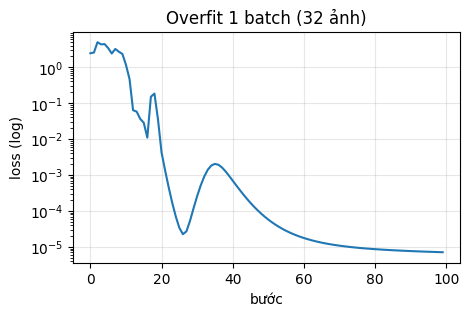

loss đầu 2.440 → loss cuối 0.0000


In [11]:
def overfit_one_batch(steps=100, n=32, lr=0.1):
    m = build_model().to(device)
    opt = torch.optim.SGD([p for p in m.parameters() if p.requires_grad], lr=lr, momentum=0.9)
    x1, y1 = xb[:n].to(device), yb[:n].to(device)
    losses = []
    for _ in range(steps):
        set_train_mode(m, freeze_backbone=True)
        loss = criterion(m(x1), y1)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses


losses = overfit_one_batch()
plt.figure(figsize=(5, 3))
plt.semilogy(losses)
plt.xlabel("bước")
plt.ylabel("loss (log)")
plt.title("Overfit 1 batch (32 ảnh)")
plt.grid(alpha=0.3)
plt.show()
print(f"loss đầu {losses[0]:.3f} → loss cuối {losses[-1]:.4f}")

> **Việc của nhóm (D1):** bổ sung *shuffled-label test*: huấn luyện với nhãn train bị xáo trộn ngẫu nhiên, val accuracy phải xấp xỉ 10%.

## 4. Huấn luyện

Vòng lặp ghi lại train/val loss, accuracy, learning rate và gradient norm của các tham số trainable. Khi phát triển mô hình, các nhóm cần bổ sung log theo **từng lớp** (gradient norm, activation stats, ‖ΔW‖/‖W‖), xem Phần D2 trong đề.

In [12]:
def grad_norm(params):
    norms = [p.grad.detach().norm() for p in params if p.grad is not None]
    return torch.stack(norms).norm().item() if norms else 0.0


def run_epoch(model, loader, optimizer=None, freeze_backbone=True):
    """Một epoch train (nếu có optimizer) hoặc eval. Trả về (loss, acc, grad_norm trung bình)."""
    is_train = optimizer is not None
    if is_train:
        set_train_mode(model, freeze_backbone)
        params = [p for p in model.parameters() if p.requires_grad]
    else:
        model.eval()
    sum_loss, correct, n, gnorms = 0.0, 0, 0, []
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            loss = criterion(logits, y)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                gnorms.append(grad_norm(params))
                optimizer.step()
            sum_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return sum_loss / n, correct / n, (float(np.mean(gnorms)) if gnorms else None)

In [13]:
set_seed(CFG["seed"])
model = build_model().to(device)
# Chỉ đưa tham số trainable vào optimizer.
optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=CFG["lr"], momentum=CFG["momentum"], weight_decay=CFG["weight_decay"],
)

history = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "lr", "grad_norm", "time"]}
best_val, best_state = -1.0, None
for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    tr_loss, tr_acc, gn = run_epoch(model, train_loader, optimizer)
    va_loss, va_acc, _ = run_epoch(model, val_loader)
    for k, v in zip(history, [epoch, tr_loss, tr_acc, va_loss, va_acc, optimizer.param_groups[0]["lr"], gn, time.time() - t0]):
        history[k].append(v)
    if va_acc > best_val:  # chọn checkpoint theo VAL, không bao giờ theo test
        best_val = va_acc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}"
          f" | grad norm {gn:.3f} | {time.time() - t0:.0f}s")

epoch  1 | train loss 1.7712 acc 0.4576 | val loss 1.4570 acc 0.5128 | grad norm 2.921 | 18s
epoch  2 | train loss 1.1456 acc 0.7106 | val loss 1.0859 acc 0.6714 | grad norm 2.301 | 21s
epoch  3 | train loss 0.9144 acc 0.7668 | val loss 0.9120 acc 0.7400 | grad norm 2.009 | 18s
epoch  4 | train loss 0.7925 acc 0.7894 | val loss 0.8187 acc 0.7568 | grad norm 1.769 | 18s
epoch  5 | train loss 0.7213 acc 0.8078 | val loss 0.7937 acc 0.7408 | grad norm 1.683 | 18s
epoch  6 | train loss 0.6725 acc 0.8152 | val loss 0.7273 acc 0.7726 | grad norm 1.624 | 20s
epoch  7 | train loss 0.6350 acc 0.8226 | val loss 0.6779 acc 0.7852 | grad norm 1.614 | 18s
epoch  8 | train loss 0.6043 acc 0.8314 | val loss 0.6651 acc 0.7918 | grad norm 1.508 | 18s
epoch  9 | train loss 0.5803 acc 0.8380 | val loss 0.6194 acc 0.8168 | grad norm 1.397 | 18s
epoch 10 | train loss 0.5605 acc 0.8402 | val loss 0.6175 acc 0.8044 | grad norm 1.435 | 20s


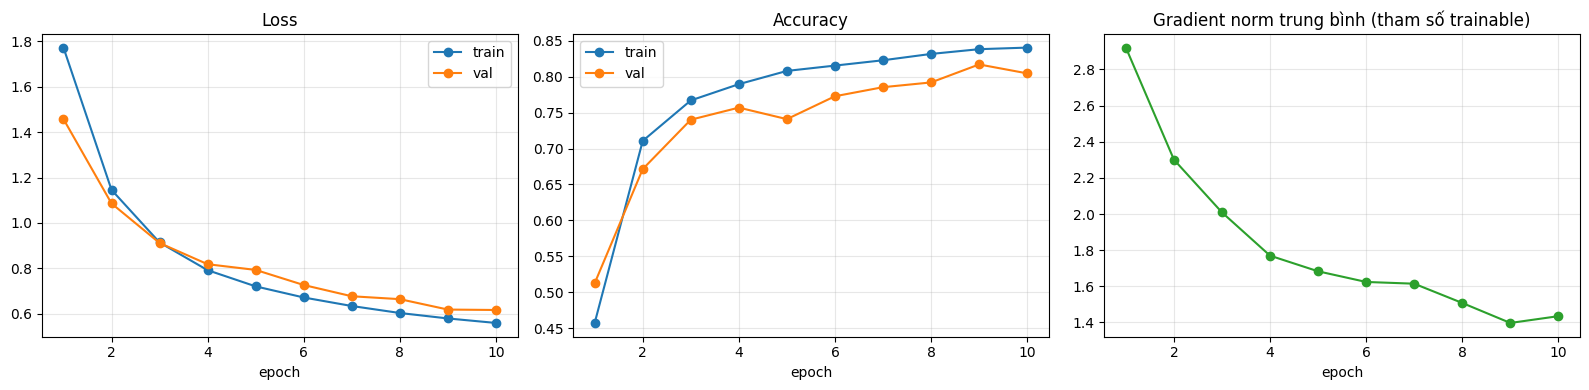

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ep = history["epoch"]
axes[0].plot(ep, history["train_loss"], "o-", label="train")
axes[0].plot(ep, history["val_loss"], "o-", label="val")
axes[0].set_title("Loss")
axes[1].plot(ep, history["train_acc"], "o-", label="train")
axes[1].plot(ep, history["val_acc"], "o-", label="val")
axes[1].set_title("Accuracy")
axes[2].plot(ep, history["grad_norm"], "o-", color="C2")
axes[2].set_title("Gradient norm trung bình (tham số trainable)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Đánh giá trên tập test

Chỉ chạy **một lần** với checkpoint đã chọn theo val. Không dùng kết quả này để quay lại chỉnh hyperparameter.

Best val acc: 0.8168 | TEST ACC: 0.8132
    airplane: 0.900
  automobile: 0.820
        bird: 0.700
         cat: 0.650
        deer: 0.763
         dog: 0.816
        frog: 0.885
       horse: 0.764
        ship: 0.900
       truck: 0.934


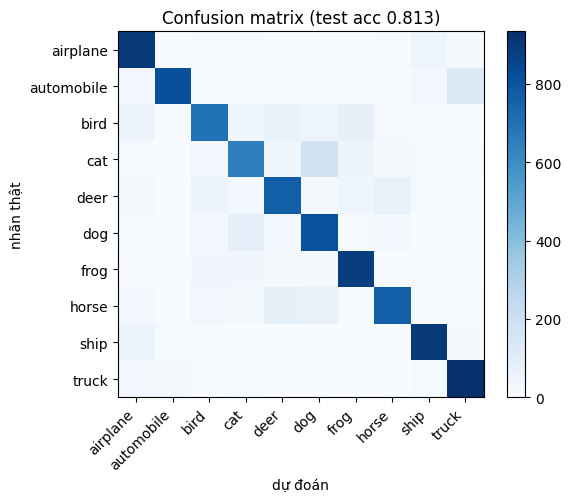

In [15]:
model.load_state_dict(best_state)
model.eval()
all_pred, all_true = [], []
with torch.no_grad():
    for x, y in test_loader:
        all_pred.append(model(x.to(device)).argmax(1).cpu())
        all_true.append(y)
all_pred, all_true = torch.cat(all_pred).numpy(), torch.cat(all_true).numpy()
test_acc = float((all_pred == all_true).mean())
print(f"Best val acc: {best_val:.4f} | TEST ACC: {test_acc:.4f}")

cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (all_true, all_pred), 1)
per_class = cm.diagonal() / cm.sum(1)
for c, a in zip(CLASSES, per_class):
    print(f"  {c:>10s}: {a:.3f}")

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), CLASSES, rotation=45, ha="right")
plt.yticks(range(10), CLASSES)
plt.xlabel("dự đoán")
plt.ylabel("nhãn thật")
plt.title(f"Confusion matrix (test acc {test_acc:.3f})")
plt.colorbar()
plt.tight_layout()
plt.show()

## 6. Lưu checkpoint và kết quả

Checkpoint lưu kèm thông tin tiền xử lý (`img_size`, `mean`, `std`) để demo dùng **đúng** pipeline lúc train.

In [16]:
ckpt_path = os.path.join(CFG["out_dir"], "baseline_resnet18.pt")
torch.save({
    "arch": "resnet18",
    "state_dict": best_state,
    "num_classes": 10,
    "classes": CLASSES,
    "img_size": CFG["img_size"],
    "mean": IMAGENET_MEAN,
    "std": IMAGENET_STD,
    "cfg": CFG,
    "val_acc": best_val,
    "test_acc": test_acc,
}, ckpt_path)
with open(os.path.join(CFG["out_dir"], "baseline_results.json"), "w") as f:
    json.dump({"cfg": CFG, "history": history, "best_val_acc": best_val, "test_acc": test_acc,
               "per_class_acc": dict(zip(CLASSES, per_class.round(4).tolist()))}, f, indent=2)
print("Đã lưu:", ckpt_path)

# Trên Colab, nên chép checkpoint sang Google Drive để không bị mất:
# from google.colab import drive; drive.mount("/content/drive")
# !cp outputs/baseline_resnet18.pt /content/drive/MyDrive/

Đã lưu: ./outputs/baseline_resnet18.pt


## 7. Hàm `predict()` cho demo

`demo/app_gradio.py` dùng đúng logic này: đọc checkpoint, dựng lại mô hình và tiền xử lý ảnh **giống hệt lúc eval**.

In [17]:
from PIL import Image


def load_checkpoint(path, map_location="cpu"):
    ckpt = torch.load(path, map_location=map_location, weights_only=False)
    m = getattr(torchvision.models, ckpt["arch"])(weights=None, num_classes=ckpt["num_classes"])
    m.load_state_dict(ckpt["state_dict"])
    m.eval()
    tf = T.Compose([
        T.Resize((ckpt["img_size"], ckpt["img_size"])),
        T.ToTensor(),
        T.Normalize(ckpt["mean"], ckpt["std"]),
    ])
    return m, tf, ckpt["classes"]


@torch.no_grad()
def predict(img, model, tf, classes, k=5):
    x = tf(img.convert("RGB")).unsqueeze(0)
    probs = model(x).softmax(1)[0]
    top = probs.topk(k)
    return [(classes[i], float(p)) for p, i in zip(top.values, top.indices)]


demo_model, demo_tf, demo_classes = load_checkpoint(ckpt_path)
raw_test = torchvision.datasets.CIFAR10(CFG["data_dir"], train=False, download=False)
img, label = raw_test[0]
print("nhãn thật:", CLASSES[label])
for name, p in predict(img, demo_model, demo_tf, demo_classes):
    print(f"  {name:>10s}: {p:.3f}")

nhãn thật: cat
         dog: 0.324
         cat: 0.319
        frog: 0.082
       truck: 0.072
        bird: 0.056


## 8. Từ baseline đến mô hình của nhóm

Baseline cố ý để lại nhiều chỗ chưa tối ưu. Một số câu hỏi gợi mở (không phải đáp án):

- Linear probe chỉ huấn luyện ~0,05% tham số. Mở khoá thêm các lớp thì sao? Với learning rate bao nhiêu?
- SGD không momentum với LR cố định có phải lựa chọn tốt? Hãy làm LR range test.
- Mô hình có đang overfit hay underfit? Đường train/val ở trên nói gì?
- Augmentation nào hợp với ảnh 32×32 được phóng lên 224×224?
- Ảnh CIFAR rất nhỏ. Có cần đúng 224×224 không? Đánh đổi giữa độ chính xác và thời gian ra sao?
- Những lớp nào hay bị nhầm (xem confusion matrix)? Vì sao?

Ghi lại **mọi** thí nghiệm (cấu hình + kết quả) để đưa vào báo cáo.